# Figure 2 - Analysis Code

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import mannwhitneyu

In [ ]:
DATA_PATH = "../../cnt-data/"

In [3]:
# This is the example patient's HUP ID
patient_hup_id = 142

# Load in the patient's "giant table"
hourly_patient_features_df = pd.read_csv(
    os.path.join(DATA_PATH, f"giant_new_tables/HUP_{str(patient_hup_id)}.csv")
)

## Figure 2 (A)

In [4]:
# Load taper_annotations.csv from the data directory
taper_df = pd.read_csv(os.path.join(DATA_PATH, "taper_annotations.csv"))
# Drop rows with any missing values in taper_start_hr
taper_df = taper_df.dropna(subset=["taper_start_hr"])
# Drop the reinit_start_hr column
taper_df = taper_df.drop(columns=["reinit_start_hr"]).reset_index(drop=True)

In [5]:
len(taper_df)

16

In [6]:
# Initialize dictionaries to store synchrony values for each hup_id
before_synchronies_dict = {}
after_synchronies_dict = {}

# Sort the hup_ids in ascending order and create a mapping to new indices
unique_hup_ids = sorted(taper_df["hup_id"].unique())
hup_id_to_index = {hup_id: index for index, hup_id in enumerate(unique_hup_ids)}

# Iterate through each row in the dataframe to collect synchrony values
for index, row in taper_df.iterrows():
    hup_id = int(row["hup_id"])
    taper_start_hr = int(row["taper_start_hr"])
    taper_start_time = taper_start_hr * 60

    hourly_patient_features_df = pd.read_csv(
        os.path.join(DATA_PATH, f"giant_new_tables/HUP_{str(patient_hup_id)}.csv")
    )

    first_seizure_time = hourly_patient_features_df[
        (hourly_patient_features_df["emu_minute"] > taper_start_time)
        & (hourly_patient_features_df["had_seizure"] >= 1)
    ]["emu_minute"].min()

    after_period = hourly_patient_features_df[
        (hourly_patient_features_df["emu_minute"] >= taper_start_time)
        & (hourly_patient_features_df["emu_minute"] < first_seizure_time)
    ]
    after_synchronies = after_period["synchrony_broadband"].values

    before_period = hourly_patient_features_df[
        (hourly_patient_features_df["emu_minute"] < taper_start_time)
        & (~hourly_patient_features_df["synchrony_broadband"].isna())
    ].tail(len(after_synchronies))
    before_synchronies = before_period["synchrony_broadband"].values

    before_synchronies = before_synchronies[~np.isnan(before_synchronies)]
    after_synchronies = after_synchronies[~np.isnan(after_synchronies)]

    # Store the 'before' and 'after' synchrony values in the corresponding dictionaries
    hup_index = hup_id_to_index[hup_id]  # Use the new index for even spacing
    if hup_index not in before_synchronies_dict:
        before_synchronies_dict[hup_index] = []
        after_synchronies_dict[hup_index] = []

    before_synchronies_dict[hup_index].extend(before_synchronies)
    after_synchronies_dict[hup_index].extend(after_synchronies)

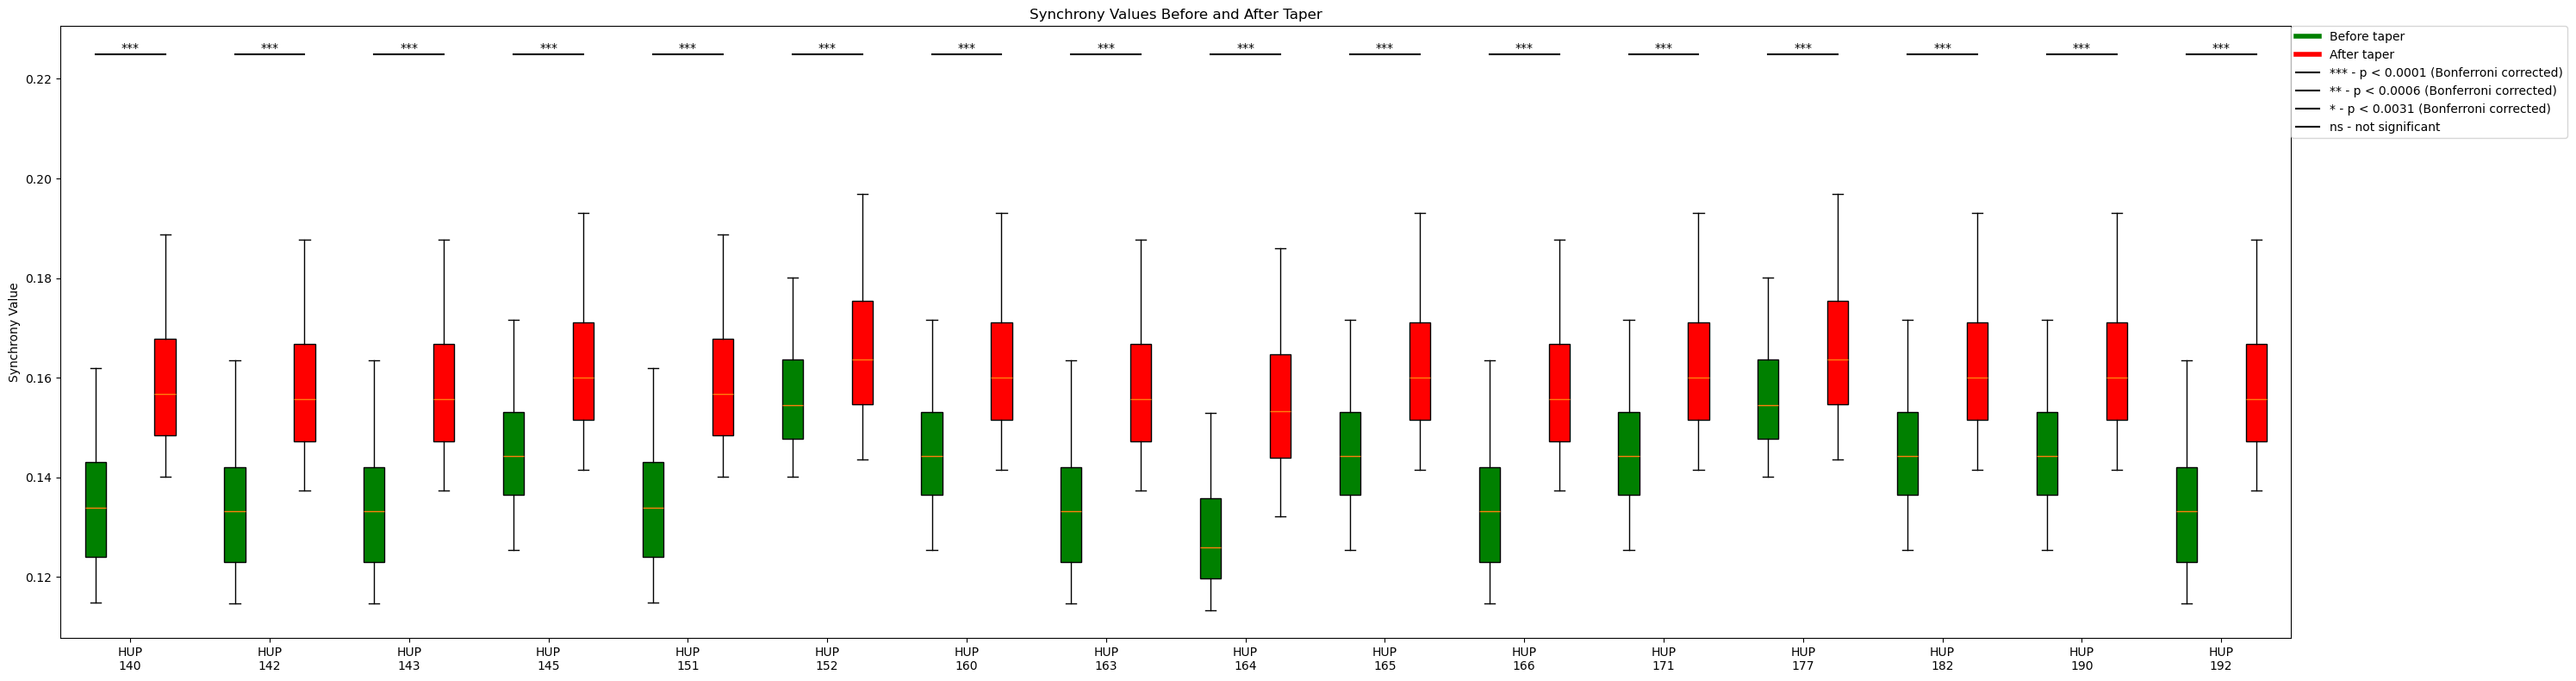

In [7]:
# Use matplotlib to create the boxplots in a wider figure
fig, ax = plt.subplots(figsize=(30, 8))  # Making the figure wider

# Define the percentile for the whiskers (e.g., 5th and 95th percentiles)
lower_whisker = 5
upper_whisker = 95

# You would have to iterate over your dictionaries to plot the 'before' and 'after' boxplots using the new indices
positions = []
labels = []
for hup_index in sorted(before_synchronies_dict.keys()):
    hup_id = unique_hup_ids[hup_index]  # Retrieve the actual hup_id for labeling
    # Calculate positions for 'before' and 'after' boxplots
    before_position = 2 * hup_index
    after_position = 2 * hup_index + 1
    # Center label position between 'before' and 'after'
    label_position = (before_position + after_position) / 2
    positions.append(label_position)
    labels.append(f"HUP\n{hup_id}")

    # Plot 'before' boxplot
    bp_before = ax.boxplot(
        before_synchronies_dict[hup_index],
        positions=[before_position],
        patch_artist=True,
        widths=0.3,
        showfliers=False,
        whis=[lower_whisker, upper_whisker],
    )
    plt.setp(bp_before["boxes"], facecolor="green")

    # Plot 'after' boxplot
    bp_after = ax.boxplot(
        after_synchronies_dict[hup_index],
        positions=[after_position],
        patch_artist=True,
        widths=0.3,
        showfliers=False,
        whis=[lower_whisker, upper_whisker],
    )
    plt.setp(bp_after["boxes"], facecolor="red")

    # Statistical test and significance annotation
    u_statistic, p_value = mannwhitneyu(
        before_synchronies_dict[hup_index],
        after_synchronies_dict[hup_index],
        alternative="two-sided",
    )
    sig = "ns"  # Default to not significant
    # Incorporate Bonferroni correction for multiple comparisons
    if p_value < 0.05 / len(taper_df):
        sig = "*"
    if p_value < 0.01 / len(taper_df):
        sig = "**"
    if p_value < 0.001 / len(taper_df):
        sig = "***"

    # Annotation at a fixed y-value
    annotation_y = 0.225
    ax.plot(
        [before_position, after_position],
        [annotation_y, annotation_y],
        lw=1.5,
        c="black",
    )
    ax.text(
        (before_position + after_position) / 2,
        annotation_y,
        sig,
        ha="center",
        va="bottom",
        color="black",
    )

# Adjusting x-axis labels
ax.set_ylabel("Synchrony Value")
ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=0)  # Labels are now more concise
plt.title("Synchrony Values Before and After Taper")

# Updating the legend to account for Bonferroni correction and placing it outside the plot
bonferroni_corrected_05 = 0.05 / len(taper_df)
bonferroni_corrected_01 = 0.01 / len(taper_df)
bonferroni_corrected_001 = 0.001 / len(taper_df)

# Defining the legend elements
legend_elements = [
    Line2D([0], [0], color="green", lw=4, label="Before taper"),
    Line2D([0], [0], color="red", lw=4, label="After taper"),
    Line2D(
        [0],
        [0],
        color="black",
        lw=1.5,
        label=f"*** - p < {bonferroni_corrected_001:.4f} (Bonferroni corrected)",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        lw=1.5,
        label=f"** - p < {bonferroni_corrected_01:.4f} (Bonferroni corrected)",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        lw=1.5,
        label=f"* - p < {bonferroni_corrected_05:.4f} (Bonferroni corrected)",
    ),
    Line2D([0], [0], color="black", lw=1.5, label="ns - not significant"),
]

# Placing the legend outside the plot
ax.legend(
    handles=legend_elements, loc="upper left", bbox_to_anchor=(1, 1), borderaxespad=0.0
)

# Finalizing the plot
plt.tight_layout()
plt.show()

## Figure 2 (B)

In [8]:
# Load taper_annotations.csv from the data directory
reinit_df = pd.read_csv(os.path.join(DATA_PATH, "taper_annotations.csv"))
# Drop rows with any missing values in taper_start_hr
reinit_df = reinit_df.dropna(subset=["reinit_start_hr"])
# Drop the taper_start_hr column
reinit_df = reinit_df.drop(columns=["taper_start_hr"])
# reset the index
reinit_df = reinit_df.reset_index(drop=True)

In [9]:
# Remove the row with hup_id == 152
reinit_df = reinit_df[reinit_df["hup_id"] != 152]

In [10]:
len(reinit_df)

9

In [11]:
# Initialize dictionaries to store synchrony values for each hup_id
before_synchronies_dict = {}
after_synchronies_dict = {}

# Sort the hup_ids in ascending order and create a mapping to new indices
unique_hup_ids = sorted(reinit_df["hup_id"].unique())
hup_id_to_index = {hup_id: index for index, hup_id in enumerate(unique_hup_ids)}

In [12]:
# Iterate through each row in the dataframe to collect synchrony values
for index, row in reinit_df.iterrows():
    hup_id = int(row["hup_id"])
    reinit_start_hr = int(row["reinit_start_hr"])
    reinit_start_time = reinit_start_hr * 60

    hourly_patient_features_df = pd.read_csv(
        os.path.join(DATA_PATH, f"giant_new_tables/HUP_{str(patient_hup_id)}.csv")
    )

    before_period = hourly_patient_features_df[
        (hourly_patient_features_df["emu_minute"] < reinit_start_time)
        & (~hourly_patient_features_df["synchrony_broadband"].isna())
    ].tail(720)
    before_synchronies = before_period["synchrony_broadband"].values

    after_period = hourly_patient_features_df[
        (hourly_patient_features_df["emu_minute"] >= reinit_start_time)
        & (~hourly_patient_features_df["synchrony_broadband"].isna())
    ].head(720)
    after_synchronies = after_period["synchrony_broadband"].values

    before_synchronies = before_synchronies[~np.isnan(before_synchronies)]
    after_synchronies = after_synchronies[~np.isnan(after_synchronies)]

    # Store the 'before' and 'after' synchrony values in the corresponding dictionaries
    hup_index = hup_id_to_index[hup_id]  # Use the new index for even spacing
    if hup_index not in before_synchronies_dict:
        before_synchronies_dict[hup_index] = []
        after_synchronies_dict[hup_index] = []

    before_synchronies_dict[hup_index].extend(before_synchronies)
    after_synchronies_dict[hup_index].extend(after_synchronies)

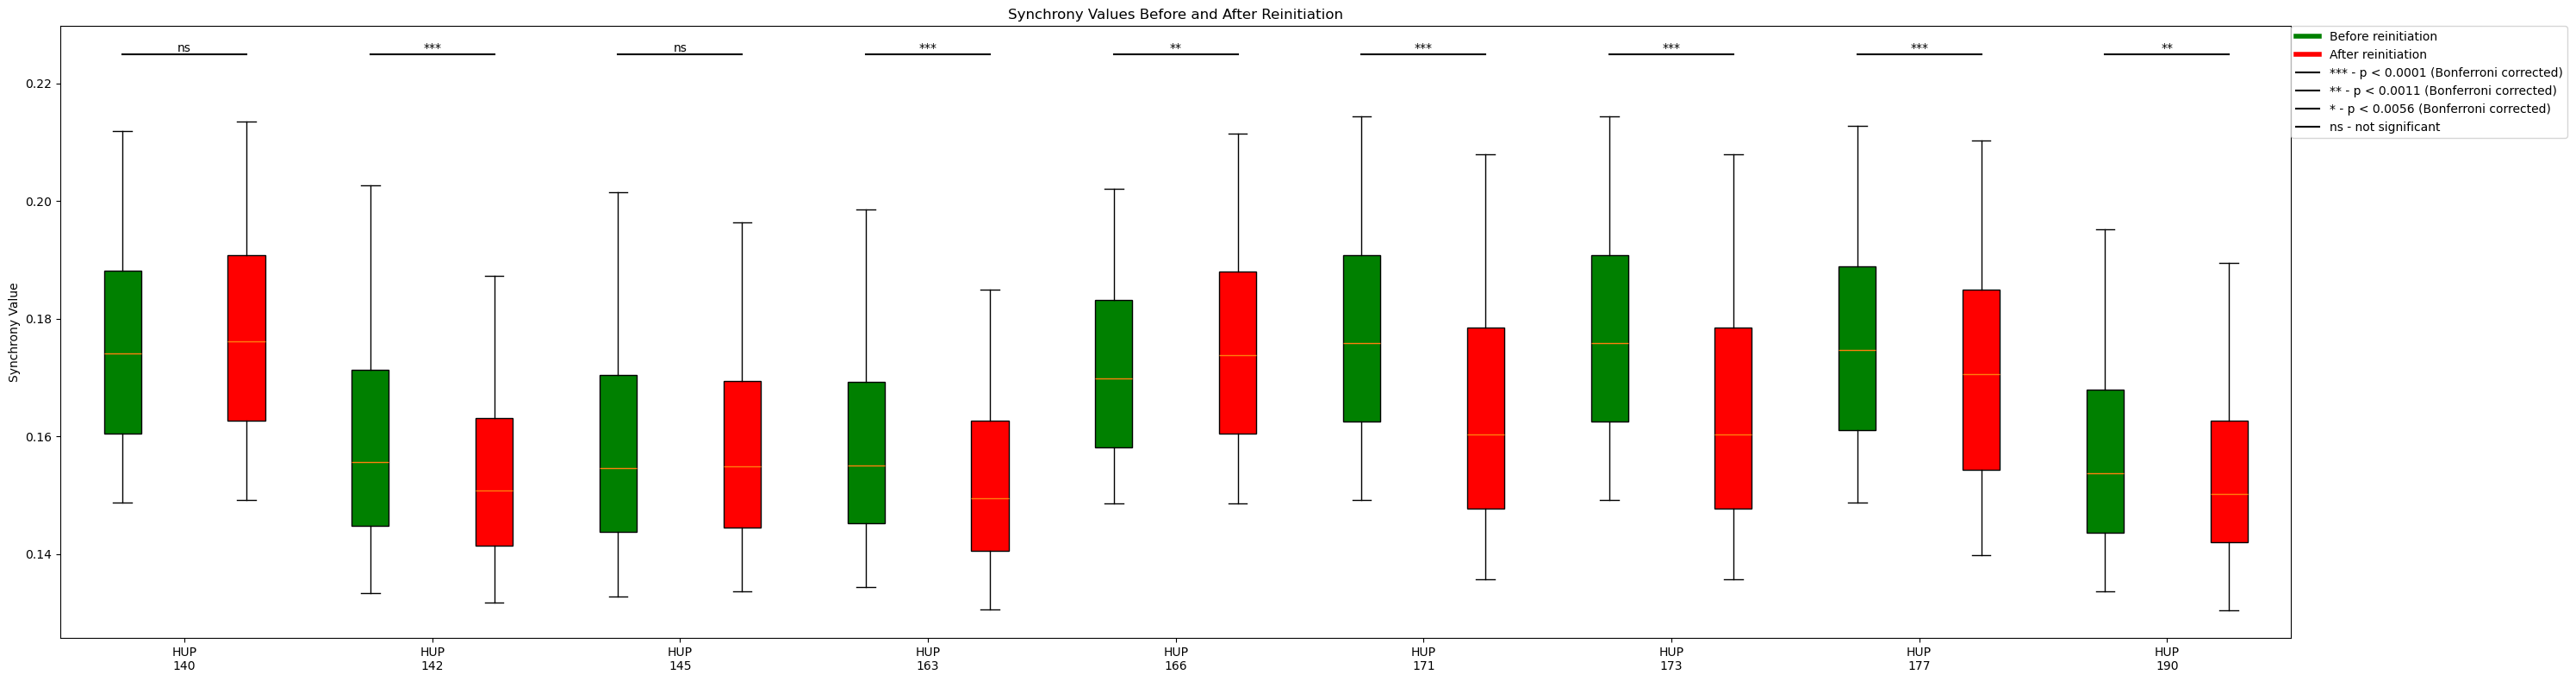

In [13]:
# Use matplotlib to create the boxplots in a wider figure
fig, ax = plt.subplots(figsize=(30, 8))  # Making the figure wider

# Define the percentile for the whiskers (e.g., 5th and 95th percentiles)
lower_whisker = 5
upper_whisker = 95

# You would have to iterate over your dictionaries to plot the 'before' and 'after' boxplots using the new indices
positions = []
labels = []
for hup_index in sorted(before_synchronies_dict.keys()):
    hup_id = unique_hup_ids[hup_index]  # Retrieve the actual hup_id for labeling
    # Calculate positions for 'before' and 'after' boxplots
    before_position = 2 * hup_index
    after_position = 2 * hup_index + 1
    # Center label position between 'before' and 'after'
    label_position = (before_position + after_position) / 2
    positions.append(label_position)
    labels.append(f"HUP\n{hup_id}")

    # Plot 'before' boxplot
    bp_before = ax.boxplot(
        before_synchronies_dict[hup_index],
        positions=[before_position],
        patch_artist=True,
        widths=0.3,
        showfliers=False,
        whis=[lower_whisker, upper_whisker],
    )
    plt.setp(bp_before["boxes"], facecolor="green")

    # Plot 'after' boxplot
    bp_after = ax.boxplot(
        after_synchronies_dict[hup_index],
        positions=[after_position],
        patch_artist=True,
        widths=0.3,
        showfliers=False,
        whis=[lower_whisker, upper_whisker],
    )
    plt.setp(bp_after["boxes"], facecolor="red")

    # Statistical test and significance annotation
    u_statistic, p_value = mannwhitneyu(
        before_synchronies_dict[hup_index],
        after_synchronies_dict[hup_index],
        alternative="two-sided",
    )
    sig = "ns"  # Default to not significant
    # Incorporate Bonferroni correction for multiple comparisons
    if p_value < 0.05 / len(reinit_df):
        sig = "*"
    if p_value < 0.01 / len(reinit_df):
        sig = "**"
    if p_value < 0.001 / len(reinit_df):
        sig = "***"

    # Annotation at a fixed y-value
    annotation_y = 0.225
    ax.plot(
        [before_position, after_position],
        [annotation_y, annotation_y],
        lw=1.5,
        c="black",
    )
    ax.text(
        (before_position + after_position) / 2,
        annotation_y,
        sig,
        ha="center",
        va="bottom",
        color="black",
    )

# Adjusting x-axis labels
ax.set_ylabel("Synchrony Value")
ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=0)  # Labels are now more concise
plt.title("Synchrony Values Before and After Reinitiation")

# Updating the legend to account for Bonferroni correction
bonferroni_corrected_05 = 0.05 / len(reinit_df)
bonferroni_corrected_01 = 0.01 / len(reinit_df)
bonferroni_corrected_001 = 0.001 / len(reinit_df)

# Updating the legend with Bonferroni corrected p-values
legend_elements = [
    Line2D([0], [0], color="green", lw=4, label="Before reinitiation"),
    Line2D([0], [0], color="red", lw=4, label="After reinitiation"),
    Line2D(
        [0],
        [0],
        color="black",
        lw=1.5,
        label=f"*** - p < {bonferroni_corrected_001:.4f} (Bonferroni corrected)",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        lw=1.5,
        label=f"** - p < {bonferroni_corrected_01:.4f} (Bonferroni corrected)",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        lw=1.5,
        label=f"* - p < {bonferroni_corrected_05:.4f} (Bonferroni corrected)",
    ),
    Line2D([0], [0], color="black", lw=1.5, label="ns - not significant"),
]

# Placing the legend outside the plot
ax.legend(
    handles=legend_elements, loc="upper left", bbox_to_anchor=(1, 1), borderaxespad=0.0
)

# Finalizing the plot
plt.tight_layout()
plt.show()